[![Open in molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/adriansousapoza/tgmm/blob/main/notebooks/06_metrics.py)

# Clustering Metrics: Evaluating Gaussian Mixture Models

This notebook evaluates clustering performance with both **unsupervised** metrics (which need only the data and the assignments) and **supervised** metrics (which compare against ground-truth labels), using `ClusteringMetrics` and the information criteria built into `GaussianMixture`. It covers both the mathematical definitions and their practical use.

**What you'll learn**

- Choose the number of components with Silhouette, Davies-Bouldin, Calinski-Harabasz, Dunn, BIC and AIC
- Compare supervised metrics (Rand/ARI, MI/NMI/AMI, FMI, homogeneity/completeness/V-measure, purity) against scikit-learn
- Build a confusion matrix and classification report after matching cluster labels to true classes
- Measure the divergence between two fitted mixtures with a Monte Carlo KL estimate

**Prerequisites:** [01 -- Gaussian Mixture Models](01_gmm.ipynb).

**See also:** the [Clustering Metrics user guide](../user-guide/clustering-metrics.md) and [13 -- Model Selection](13_model_selection.ipynb).

## Setup

The next cell imports what the notebook needs and fixes the random seeds. It expects `tgmm` to be importable: `pip install tgmm`, or `pip install -e .` from a clone of the repository. Opened with `marimo edit --sandbox`, the dependencies listed in the header of this file are installed automatically.

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import matplotlib.pyplot as plt
from tqdm import tqdm


from tgmm import GaussianMixture, ClusteringMetrics, dynamic_figsize, plot_gmm, match_predicted_to_true_labels, generate_gmm_data

plt.rcParams['figure.dpi'] = 100  # tgmm's theme uses 300 dpi; keep embedded figure outputs small

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

## Synthetic Data Generation

The synthetic dataset is generated by combining four Gaussian components:

- **Component 1:** Centered at `[0, 2]` with spherical covariance.
- **Component 2:** Centered at `[2, -2]` with spherical covariance (fewer points).
- **Component 3:** Centered at `[0, 0]` with diagonal covariance.
- **Component 4:** Centered at `[2, 2]` with full covariance.

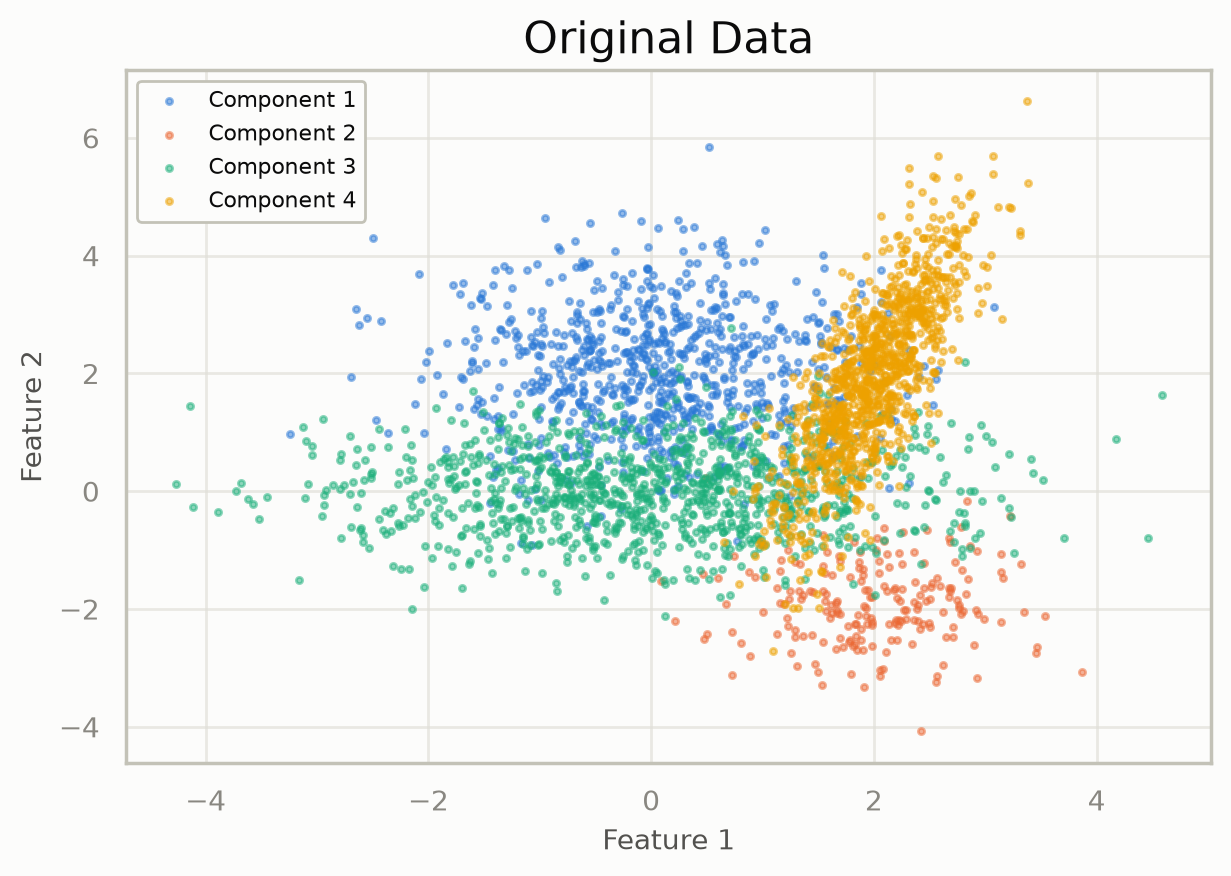

In [ ]:
n_samples = [800, 200, 1000, 1000]
centers = [np.array([0, 2]),
           np.array([2, -2]),
           np.array([0, 0]),
           np.array([2, 2])]
covs = [
    1.0 * np.eye(2),                    # spherical covariance
    0.5 * np.eye(2),                    # spherical covariance, fewer points
    np.array([[2, 0], [0, 0.5]]),       # diagonal covariance
    np.array([[0.2, 0.5], [0.5, 2]])    # full covariance
]

# Generate synthetic data using the new function
X_tensor, y_tensor = generate_gmm_data(centers, covs, n_samples, device=device, random_state=SEED)

# Convert to numpy for plotting
X = X_tensor.cpu().numpy()
labels = y_tensor.cpu().numpy()
legend_labels = [f'Component {i+1}' for i in range(len(n_samples))]

n_features = X.shape[1]
n_components = len(n_samples)

plot_gmm(X=X, true_labels=labels, title='Original Data', legend_labels=legend_labels)
plt.gcf()

## Unsupervised Clustering Metrics Definitions

Below are the definitions of the unsupervised clustering metrics used in this notebook.

### Silhouette Score

The **Silhouette Score** quantifies how similar each data point is to its own cluster compared to other clusters. For a data point $ \mathbf{x}_i $ belonging to cluster $ C_k $, the silhouette value is defined as

$$
s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}},
$$

where:
- $ a(i) $ is the average distance between $\mathbf{x}_i$ and all other points in the same cluster $ C_k $ (i.e., the intra-cluster distance),
- $ b(i) $ is the smallest average distance between $\mathbf{x}_i$ and all points in any other cluster (i.e., the nearest-cluster distance).

A high silhouette score (close to 1) indicates that the data point is well matched to its own cluster and poorly matched to neighboring clusters.

### Davies-Bouldin Index

The **Davies-Bouldin Index (DB)** measures the average similarity between each cluster and its most similar one. It is defined as

$$
\text{DB} = \frac{1}{k} \sum_{i=1}^{k} \max_{j \neq i} \frac{S_i + S_j}{M_{ij}},
$$

where:
- $ S_i $ is the average distance between the points in cluster $ i $ and the centroid of $ i $,
- $ M_{ij} $ is the distance between the centroids of clusters $ i $ and $ j $.

Lower values of the Davies-Bouldin Index indicate better clustering quality, as they reflect smaller within-cluster dispersion relative to the separation between clusters.

### Calinski-Harabasz Score

The **Calinski-Harabasz Score (CH)** (also known as the Variance Ratio Criterion) is given by

$$
\text{CH} = \frac{n-k}{k-1}\cdot\frac{\sum _{i=1}^{k}n_{i}||\mathbf {c} _{i}-\mathbf {c} ||^{2}}{\sum _{i=1}^{k}\sum _{\mathbf {x} \in C_{i}}||\mathbf {x} -\mathbf {c} _{i}||^{2}},
$$

where:
- $ k $ is the number of clusters,
- $ n $ is the total number of samples.

Higher Calinski-Harabasz scores suggest a model in which clusters are dense and well separated.

### Dunn Index

The **Dunn Index** seeks to identify clusters that are both compact and well separated. It is defined as

$$
D = \frac{\min\limits_{i \neq j} d(C_i, C_j)}{\max\limits_{k} \mathrm{diam}(C_k)},
$$

where:
- $ d(C_i, C_j) $ is the minimum distance between any two points in clusters $ C_i $ and $ C_j $,
- $ \mathrm{diam}(C_k) $ is the maximum distance between any two points in cluster $ C_k $.

A higher Dunn Index indicates better clustering, meaning that the clusters are more compact and well separated.

### Bayesian Information Criterion (BIC)

The **Bayesian Information Criterion (BIC)** is used for model selection by penalizing model complexity while rewarding goodness-of-fit. It is computed as

$$
\text{BIC} = n_{\text{params}} \cdot \ln(N) - 2 \cdot \mathcal{L},
$$

where:
- $ n_{\text{params}} $ is the number of free parameters in the model,
- $ N $ is the number of samples,
- $ \mathcal{L} $ is the *total* log-likelihood of the data under the fitted model (`GaussianMixture.bic` / `.aic` compute exactly this, with $n_{\text{params}}$ counting the mixture weights, means and covariance parameters).

Lower BIC values indicate a model that better balances fit and simplicity.

### Akaike Information Criterion (AIC)

The **Akaike Information Criterion (AIC)** is another metric for model selection defined as

$$
\text{AIC} = 2 \cdot n_{\text{params}} - 2 \cdot \mathcal{L}.
$$

As with BIC, lower AIC values suggest a model that achieves a good trade-off between complexity and fit quality.

**Note:** For selection criteria that account for cluster overlap, see ICL in [13 -- Model Selection](13_model_selection.ipynb). In practice, the ideal number of clusters is typically determined by seeking a maximum in the Silhouette Score, Calinski-Harabasz Score, and Dunn Index, while simultaneously looking for minima in the Davies-Bouldin Index, AIC, and BIC.

Evaluating range: 100%|██████████| 9/9 [00:01<00:00,  7.51it/s]


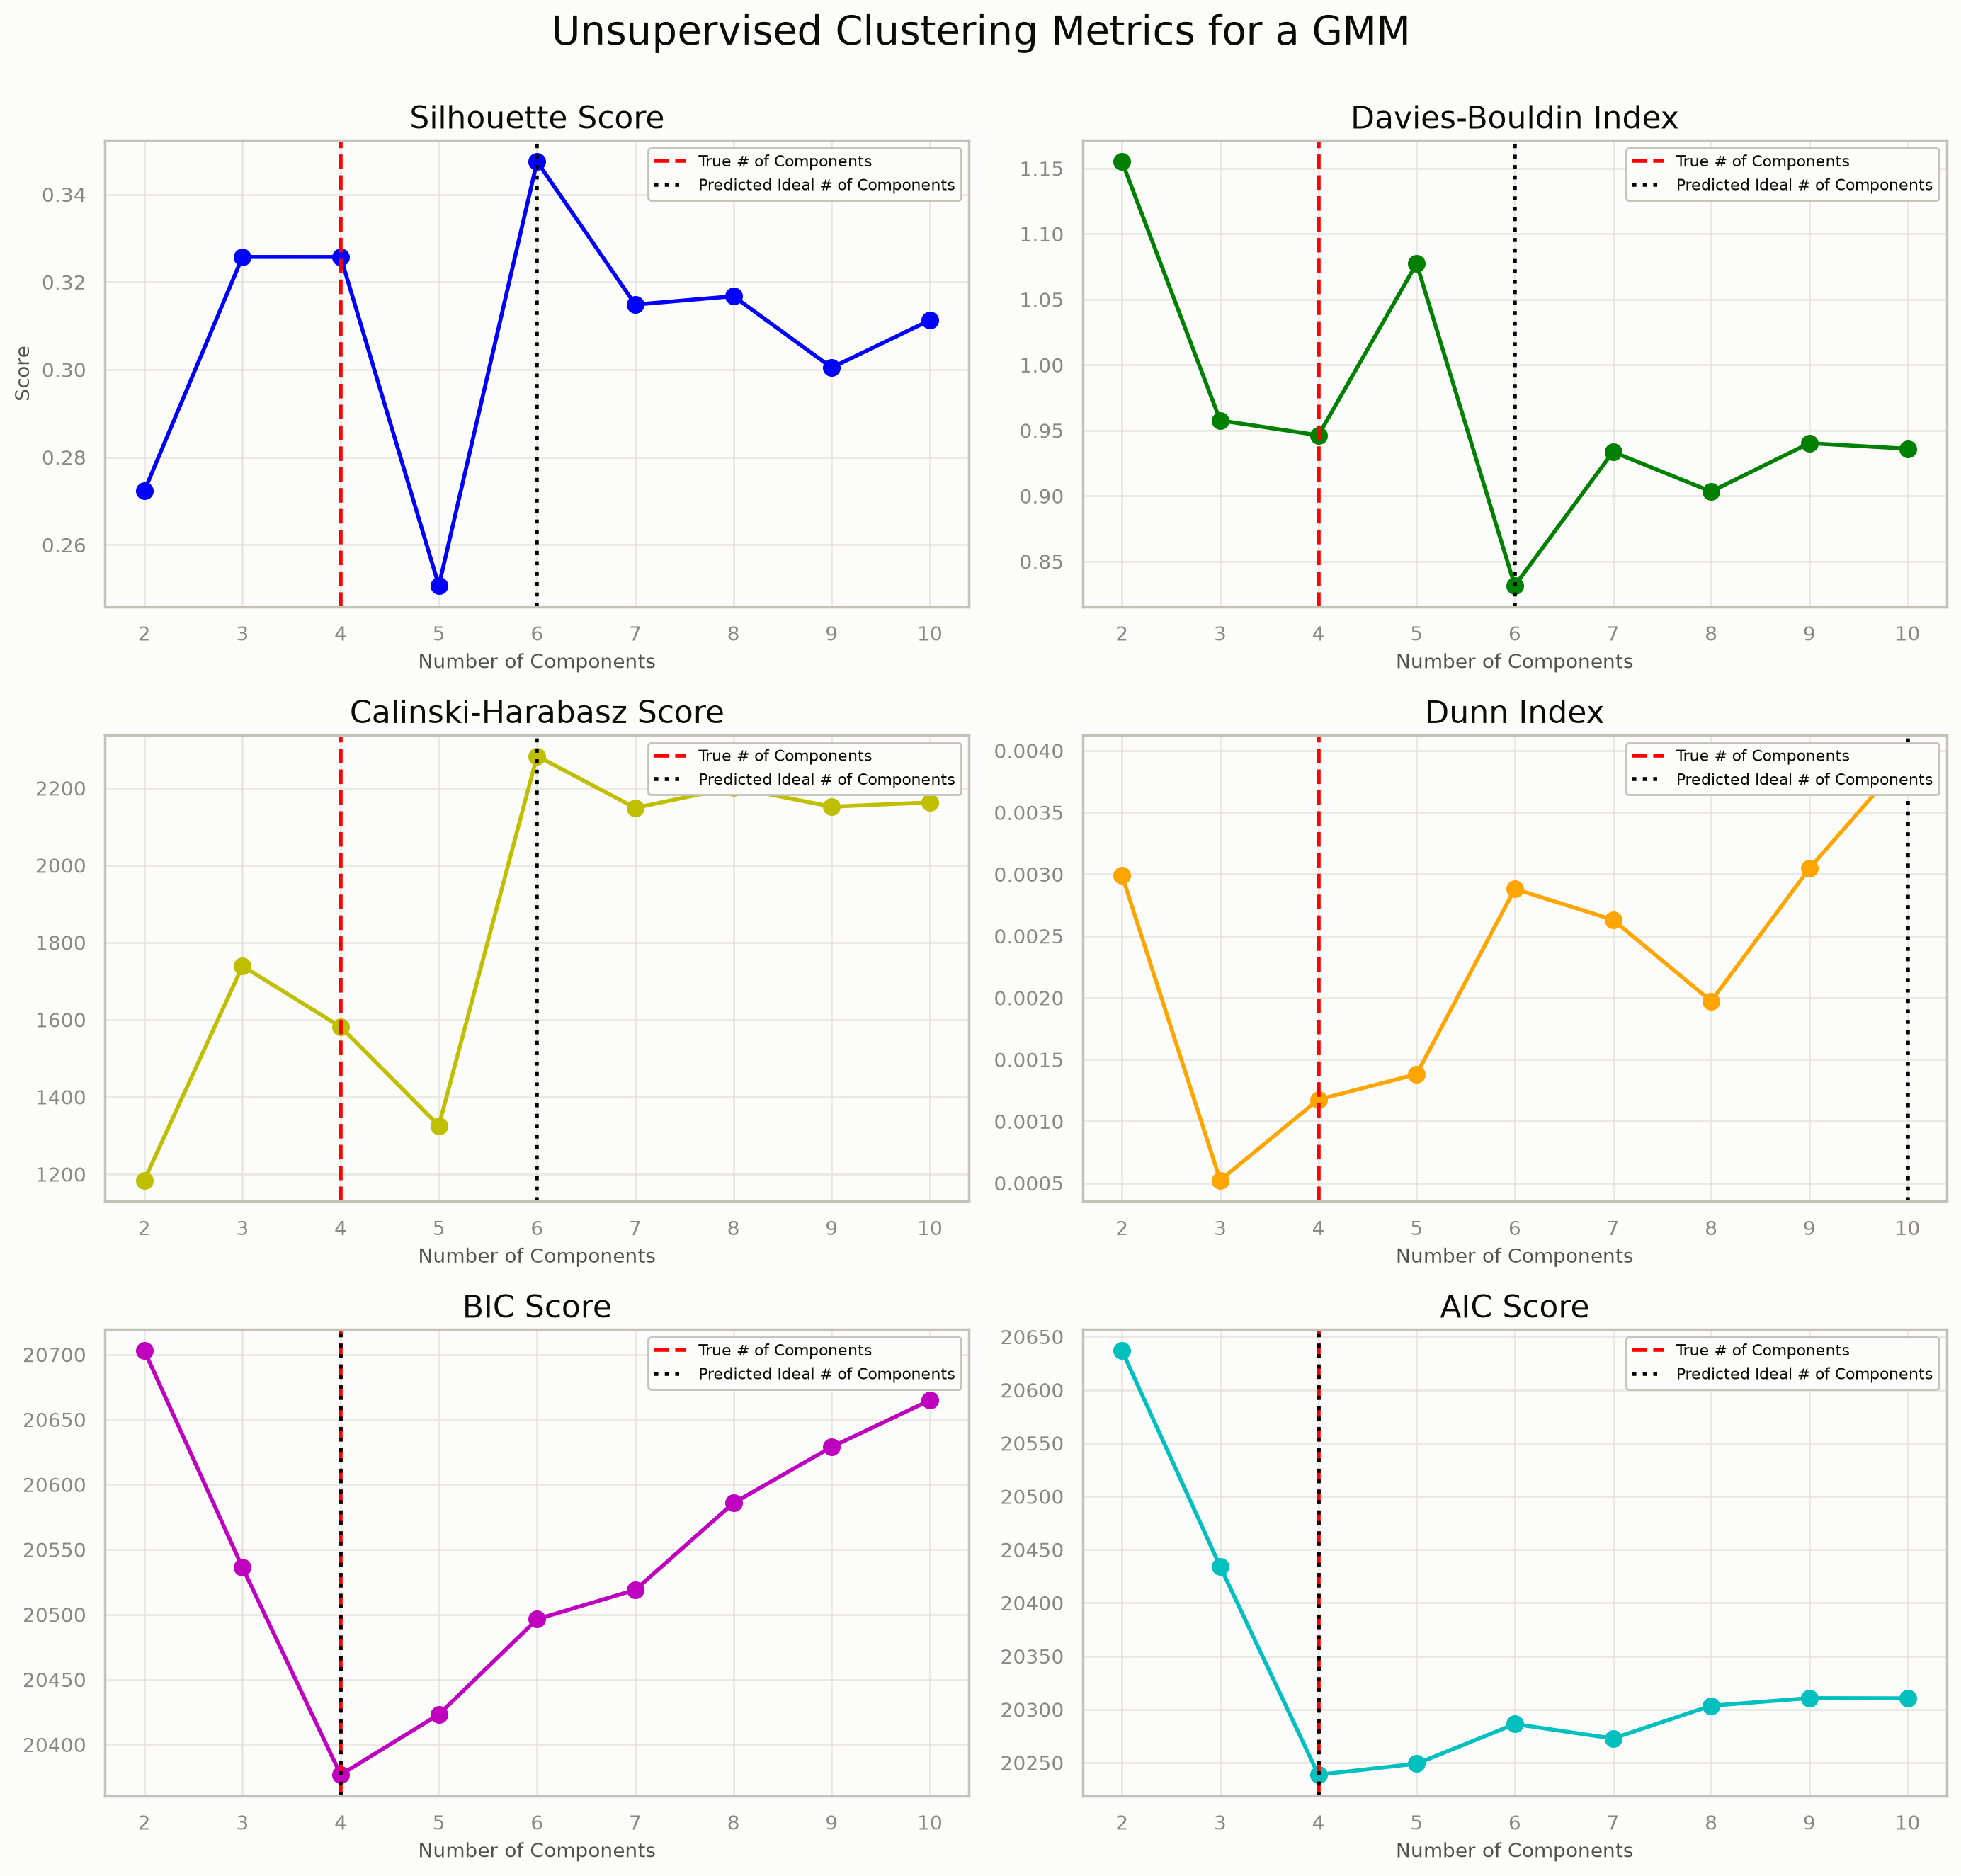

In [ ]:
components_range = np.arange(2, 11)
silhouette_vals = torch.zeros(len(components_range), device=device)
davies_vals = torch.zeros(len(components_range), device=device)
calinski_vals = torch.zeros(len(components_range), device=device)
dunn_vals = torch.zeros(len(components_range), device=device)
bic_vals = torch.zeros(len(components_range), device=device)
aic_vals = torch.zeros(len(components_range), device=device)
for _i, _n in tqdm(enumerate(components_range), total=len(components_range), desc='Evaluating range'):
# Fit a GMM for each n in components_range
    _gmm = GaussianMixture(n_features=n_features, n_components=_n, covariance_type='full', max_iter=MAX_ITER, init_means='kmeans', device=device, random_state=SEED, tol=1e-05, reg_covar=1e-07)
    _gmm.fit(X_tensor)
    labels_pred = _gmm.predict(X_tensor)
    silhouette_vals[_i] = ClusteringMetrics.silhouette_score(X_tensor, labels_pred, n_components=_n)
    davies_vals[_i] = ClusteringMetrics.davies_bouldin_index(X_tensor, labels_pred, n_components=_n)
    calinski_vals[_i] = ClusteringMetrics.calinski_harabasz_score(X_tensor, labels_pred, n_components=_n)
    dunn_vals[_i] = ClusteringMetrics.dunn_index(X_tensor, labels_pred, n_components=_n)
    bic_vals[_i] = _gmm.bic(X_tensor)
    aic_vals[_i] = _gmm.aic(X_tensor)
sil_best = components_range[torch.argmax(silhouette_vals)].item()
davies_best = components_range[torch.argmin(davies_vals)].item()
calinski_best = components_range[torch.argmax(calinski_vals)].item()
dunn_best = components_range[torch.argmax(dunn_vals)].item()  # Fit
bic_best = components_range[torch.argmin(bic_vals)].item()
aic_best = components_range[torch.argmin(aic_vals)].item()  # shape (N,)
nrows, ncols = (3, 2)
_fig, axs = plt.subplots(nrows, ncols, figsize=dynamic_figsize(nrows, ncols))  # Compute unsupervised metrics
axs[0, 0].plot(components_range, silhouette_vals.cpu(), 'o-b')
axs[0, 0].axvline(x=n_components, color='r', linestyle='--', label='True # of Components')
axs[0, 0].axvline(x=sil_best, color='k', linestyle=':', label='Predicted Ideal # of Components')
axs[0, 0].set_title('Silhouette Score')
axs[0, 0].set_xlabel('Number of Components')
axs[0, 0].set_ylabel('Score')
axs[0, 0].grid(True)
# Compute the predicted ideal number of components for each metric
axs[0, 0].legend(loc='upper right')
axs[0, 1].plot(components_range, davies_vals.cpu(), 'o-g')
axs[0, 1].axvline(x=n_components, color='r', linestyle='--', label='True # of Components')
axs[0, 1].axvline(x=davies_best, color='k', linestyle=':', label='Predicted Ideal # of Components')
axs[0, 1].set_title('Davies-Bouldin Index')
axs[0, 1].set_xlabel('Number of Components')
axs[0, 1].grid(True)
# Create a 3-rows x 2-columns figure (3 rows, 2 columns)
axs[0, 1].legend(loc='upper right')
axs[1, 0].plot(components_range, calinski_vals.cpu(), 'o-y')
axs[1, 0].axvline(x=n_components, color='r', linestyle='--', label='True # of Components')
# 1) Silhouette Score (Row 1, Col 1)
axs[1, 0].axvline(x=calinski_best, color='k', linestyle=':', label='Predicted Ideal # of Components')
axs[1, 0].set_title('Calinski-Harabasz Score')
axs[1, 0].set_xlabel('Number of Components')
axs[1, 0].grid(True)
axs[1, 0].legend(loc='upper right')
axs[1, 1].plot(components_range, dunn_vals.cpu(), 'o-', color='orange')
axs[1, 1].axvline(x=n_components, color='r', linestyle='--', label='True # of Components')
axs[1, 1].axvline(x=dunn_best, color='k', linestyle=':', label='Predicted Ideal # of Components')
axs[1, 1].set_title('Dunn Index')
# 2) Davies-Bouldin Index (Row 1, Col 2)
axs[1, 1].set_xlabel('Number of Components')
axs[1, 1].grid(True)
axs[1, 1].legend(loc='upper right')
axs[2, 0].plot(components_range, bic_vals.cpu(), 'o-m')
axs[2, 0].axvline(x=n_components, color='r', linestyle='--', label='True # of Components')
axs[2, 0].axvline(x=bic_best, color='k', linestyle=':', label='Predicted Ideal # of Components')
axs[2, 0].set_title('BIC Score')
axs[2, 0].set_xlabel('Number of Components')
# 3) Calinski-Harabasz Score (Row 2, Col 1)
axs[2, 0].grid(True)
axs[2, 0].legend(loc='upper right')
axs[2, 1].plot(components_range, aic_vals.cpu(), 'o-c')
axs[2, 1].axvline(x=n_components, color='r', linestyle='--', label='True # of Components')
axs[2, 1].axvline(x=aic_best, color='k', linestyle=':', label='Predicted Ideal # of Components')
axs[2, 1].set_title('AIC Score')
axs[2, 1].set_xlabel('Number of Components')
axs[2, 1].grid(True)
# 4) Dunn Index (Row 2, Col 2)
axs[2, 1].legend(loc='upper right')
plt.suptitle('Unsupervised Clustering Metrics for a GMM')
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.gcf()

In [ ]:
print('=== Best Number of Components According to Each Metric ===')
print(f'Silhouette Best: {sil_best}')
print(f'Davies-Bouldin Best (lowest): {davies_best}')
print(f'Calinski-Harabasz Best: {calinski_best}')
# 5) BIC Score (Row 3, Col 1)
print(f'Dunn Index Best: {dunn_best}')
print(f'BIC Best (lowest): {bic_best}')
# 6) AIC Score (Row 3, Col 2)
print(f'AIC Best (lowest): {aic_best}')

=== Best Number of Components According to Each Metric ===
Silhouette Best: 6
Davies-Bouldin Best (lowest): 6
Calinski-Harabasz Best: 6
Dunn Index Best: 10
BIC Best (lowest): 4
AIC Best (lowest): 4


## Supervised Clustering Metrics Definitions

When ground truth labels are available, we can evaluate clustering performance using supervised metrics that measure the agreement between predicted and true cluster assignments.

### Rand Index (RI)

The **Rand Index** measures the similarity between two clusterings by considering all pairs of samples and counting pairs that are assigned to the same or different clusters in both clusterings.

$$
\text{RI} = \frac{TP + TN}{TP + TN + FP + FN}
$$

where:
- $TP$ (True Positives): pairs that are in the same cluster in both clusterings
- $TN$ (True Negatives): pairs that are in different clusters in both clusterings
- $FP$ (False Positives): pairs that are in the same cluster in predicted but different clusters in true
- $FN$ (False Negatives): pairs that are in different clusters in predicted but same cluster in true

The Rand Index ranges from 0 to 1, where 1 indicates perfect agreement.

### Adjusted Rand Index (ARI)

The **Adjusted Rand Index** corrects the Rand Index for chance by subtracting the expected value and normalizing by the maximum possible value:

$$
\text{ARI} = \frac{\text{RI} - \mathbb{E}[\text{RI}]}{\max(\text{RI}) - \mathbb{E}[\text{RI}]}
$$

More explicitly, using the contingency table approach:

$$
\text{ARI} = \frac{\sum_{ij} \binom{n_{ij}}{2} - \left[\sum_i \binom{a_i}{2} \sum_j \binom{b_j}{2}\right] / \binom{n}{2}}{\frac{1}{2}\left[\sum_i \binom{a_i}{2} + \sum_j \binom{b_j}{2}\right] - \left[\sum_i \binom{a_i}{2} \sum_j \binom{b_j}{2}\right] / \binom{n}{2}}
$$

where $n_{ij}$ is the number of samples in cluster $i$ of the true clustering and cluster $j$ of the predicted clustering. ARI is at most 1 (perfect agreement), is about 0 for random labeling, and can be negative for worse-than-chance agreement.

### Mutual Information (MI)

**Mutual Information** measures the amount of information obtained about one clustering by observing the other:

$$
\text{MI}(U,V) = \sum_{i=1}^{|U|} \sum_{j=1}^{|V|} P(i,j) \log\frac{P(i,j)}{P(i)P(j)}
$$

where:
- $U$ and $V$ are the true and predicted clusterings
- $P(i,j) = \frac{|U_i \cap V_j|}{N}$ is the probability that a point belongs to clusters $U_i$ and $V_j$
- $P(i) = \frac{|U_i|}{N}$ and $P(j) = \frac{|V_j|}{N}$ are marginal probabilities

### Normalized Mutual Information (NMI)

**Normalized Mutual Information** scales MI to the range [0,1] by normalizing with the entropy of the clusterings:

$$
\text{NMI}(U,V) = \frac{2 \times \text{MI}(U,V)}{H(U) + H(V)}
$$

where $H(U) = -\sum_{i=1}^{|U|} P(i) \log P(i)$ is the entropy of clustering $U$.

### Adjusted Mutual Information (AMI)

**Adjusted Mutual Information** corrects MI for chance, similar to how ARI corrects RI:

$$
\text{AMI}(U,V) = \frac{\text{MI}(U,V) - \mathbb{E}[\text{MI}(U,V)]}{\tfrac{1}{2}\big(H(U) + H(V)\big) - \mathbb{E}[\text{MI}(U,V)]}
$$

where the expectation is the exact hypergeometric expectation over random labelings with the same cluster sizes (Vinh, Epps & Bailey, 2010; the arithmetic-mean normalizer is scikit-learn's default, and `average_method` selects 'min', 'max' or 'geometric'). `tgmm` computes it exactly, so its AMI agrees with scikit-learn's to numerical precision -- the comparison table below shows it.

### Fowlkes-Mallows Index (FMI)

The **Fowlkes-Mallows Index** is the geometric mean of pairwise precision and recall:

$$
\text{FMI} = \sqrt{\frac{TP}{TP + FP} \times \frac{TP}{TP + FN}} = \sqrt{\text{Precision} \times \text{Recall}}
$$

where TP, FP, and FN are defined as in the Rand Index but for pairwise comparisons.

### Homogeneity and Completeness

**Homogeneity** measures whether each cluster contains only members of a single class:

$$
h = 1 - \frac{H(C|K)}{H(C)}
$$

**Completeness** measures whether all members of a given class are assigned to the same cluster:

$$
c = 1 - \frac{H(K|C)}{H(K)}
$$

where $H(C|K)$ is the conditional entropy of the true classes given the cluster assignments.

### V-Measure

The **V-Measure** is the harmonic mean of homogeneity and completeness:

$$
\text{V} = \frac{2 \times h \times c}{h + c}
$$

### Purity

**Purity** measures the extent to which clusters contain a single class:

$$
\text{Purity} = \frac{1}{N} \sum_{k=1}^{K} \max_j |C_k \cap T_j|
$$

where $C_k$ is the set of samples in cluster $k$ and $T_j$ is the set of samples in true class $j$.

**Interpretation Guidelines:**
- **Higher is better**: RI, ARI, MI, NMI, AMI, FMI, Homogeneity, Completeness, V-Measure, Purity
- **Range [0,1]**: RI, NMI, FMI, Homogeneity, Completeness, V-Measure and Purity (AMI is nominally in [0,1], and can dip slightly below 0 for near-random labelings)
- **Other ranges**: ARI can be negative; MI is non-negative but not capped at 1 (it is bounded by $\min(H(U), H(V))$)
- **Perfect clustering**: RI, ARI, NMI, AMI, FMI, Homogeneity, Completeness, V-Measure and Purity all equal 1

/opt/hostedtoolcache/Python/3.11.17/x64/lib/python3.11/site-packages/sklearn/mixture/_base.py:293: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


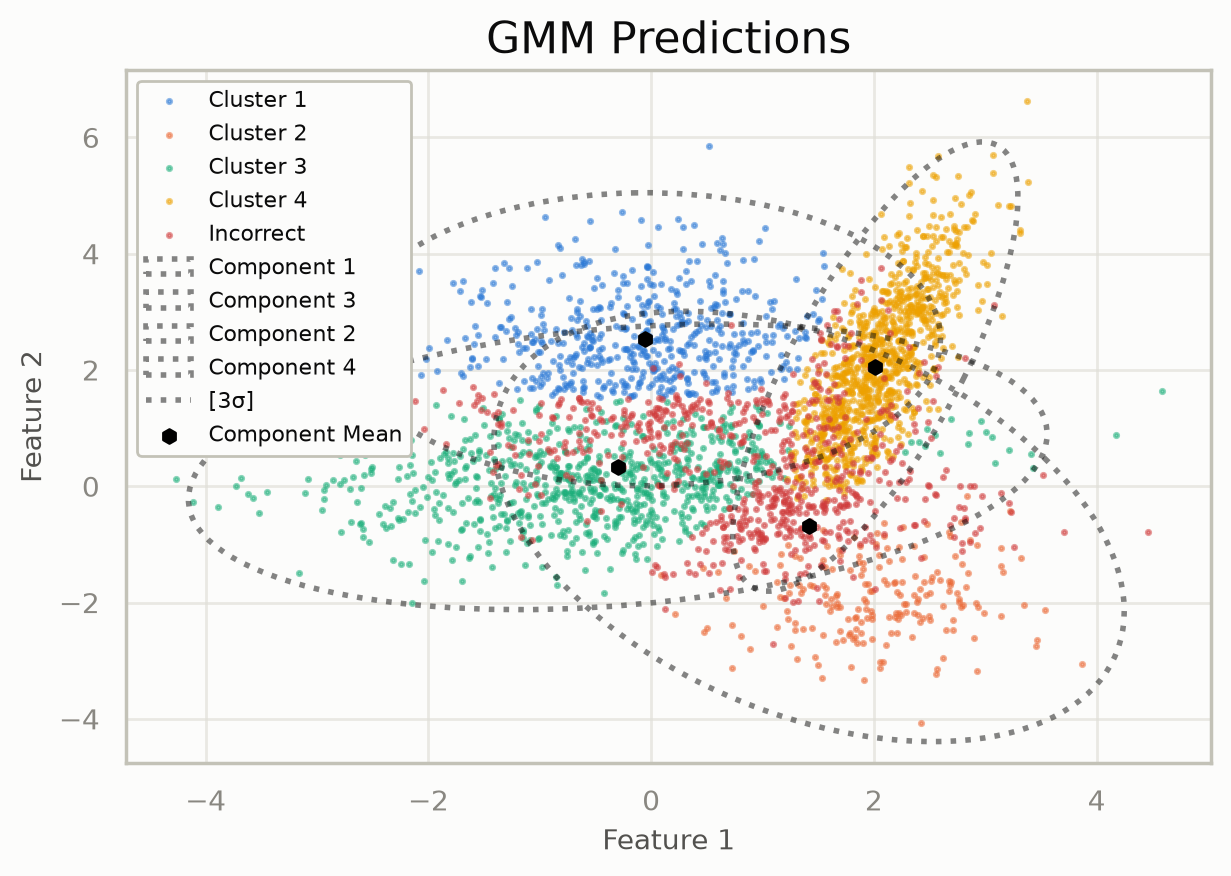

In [ ]:
from sklearn.mixture import GaussianMixture as SklearnGMM
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score, normalized_mutual_info_score, fowlkes_mallows_score, homogeneity_score, mutual_info_score, adjusted_mutual_info_score, completeness_score, v_measure_score, rand_score
_gmm = GaussianMixture(n_features=n_features, n_components=n_components, covariance_type='full', max_iter=MAX_ITER, init_means='kmeans', device=device)
_gmm.fit(X_tensor)
labels_pred_1 = _gmm.predict(X_tensor)
metrics_to_compare = ['rand_score', 'adjusted_rand_score', 'mutual_info_score', 'normalized_mutual_info_score', 'adjusted_mutual_info_score', 'fowlkes_mallows_score', 'homogeneity_score', 'completeness_score', 'v_measure_score', 'silhouette_score', 'davies_bouldin_index', 'calinski_harabasz_score', 'purity_score', 'dunn_index', 'bic_score', 'aic_score']
scores_torch = ClusteringMetrics.evaluate_clustering(_gmm, X_tensor, true_labels=y_tensor, metrics=metrics_to_compare)
scores_torch['bic_score'] = _gmm.bic(X_tensor)
scores_torch['aic_score'] = _gmm.aic(X_tensor)
X_np = X_tensor.cpu().numpy()
y_np = y_tensor.cpu().numpy()
labels_pred_np = labels_pred_1.cpu().numpy()
sk_gmm = SklearnGMM(n_components=n_components, covariance_type='full', max_iter=MAX_ITER, init_params='kmeans', random_state=SEED, tol=1e-05, reg_covar=1e-07)
sk_gmm.fit(X_np)
scores_sklearn = {'rand_score': rand_score(y_np, labels_pred_np), 'adjusted_rand_score': adjusted_rand_score(y_np, labels_pred_np), 'mutual_info_score': mutual_info_score(y_np, labels_pred_np), 'normalized_mutual_info_score': normalized_mutual_info_score(y_np, labels_pred_np), 'adjusted_mutual_info_score': adjusted_mutual_info_score(y_np, labels_pred_np), 'fowlkes_mallows_score': fowlkes_mallows_score(y_np, labels_pred_np), 'homogeneity_score': homogeneity_score(y_np, labels_pred_np), 'completeness_score': completeness_score(y_np, labels_pred_np), 'v_measure_score': v_measure_score(y_np, labels_pred_np), 'silhouette_score': silhouette_score(X_np, labels_pred_np), 'davies_bouldin_index': davies_bouldin_score(X_np, labels_pred_np), 'calinski_harabasz_score': calinski_harabasz_score(X_np, labels_pred_np)}
sk_bic = sk_gmm.bic(X_np)
sk_aic = sk_gmm.aic(X_np)
rows = []
for metric in metrics_to_compare:
    torch_val = scores_torch.get(metric, None)
    if metric in scores_sklearn:
        sklearn_val = scores_sklearn.get(metric)
    elif metric == 'bic_score':
        sklearn_val = sk_bic
    elif metric == 'aic_score':
        sklearn_val = sk_aic
    else:
        sklearn_val = None
    if torch_val is not None and sklearn_val is not None:
        abs_diff = abs(torch_val - sklearn_val)
        rel_diff = abs_diff / abs(sklearn_val) * 100 if sklearn_val != 0 else None
    else:
        abs_diff = None
        rel_diff = None
    rows.append({'Metric': metric, 'Torch Score': torch_val, 'Sklearn Score': sklearn_val, 'Absolute Difference': abs_diff, 'Relative Difference (%)': rel_diff})
_fig, ax = plt.subplots()
plot_gmm(X=X_np, gmm=_gmm, true_labels=y_tensor, match_labels_to_true=True, ax=ax, title='GMM Predictions', show_ellipses=True, show_incorrect_predictions=True, ellipse_fill=False, ellipse_std_devs=[3], point_size=10)
plt.gcf()

## Model Comparison: tgmm vs scikit-learn

This section compares the clustering metrics computed by `tgmm`'s implementation with scikit-learn's implementations to validate correctness and highlight any differences in computation methods.

### Metrics Comparison Table

The table below shows side-by-side comparisons of metrics computed using both implementations. Small differences may occur due to:
- Different numerical precision
- Slightly different algorithmic implementations
- Different handling of edge cases (e.g., single-point clusters)
- BIC/AIC come from two independently fitted models (`tgmm`'s and scikit-learn's), so they agree only approximately

**Key observations:**
- **Information-theoretic metrics** (MI, NMI, AMI) agree with scikit-learn to numerical precision
- **Pairwise metrics** (RI, ARI, FMI) should match exactly for identical cluster assignments
- **Geometric metrics** (Silhouette, Davies-Bouldin, Calinski-Harabasz) may show small differences due to distance computation methods

In [ ]:
df_metrics = pd.DataFrame(rows)
df_metrics

,Metric,Torch Score,Sklearn Score,Absolute Difference,Relative Difference (%)
0,rand_score,0.806623,0.806623,0.000000e+00,0.000000e+00
1,adjusted_rand_score,0.530833,0.530833,0.000000e+00,0.000000e+00
2,mutual_info_score,0.697030,0.697030,0.000000e+00,0.000000e+00
3,normalized_mutual_info_score,0.539595,0.539595,4.440892e-16,8.230048e-14
4,adjusted_mutual_info_score,0.539058,0.539058,8.881784e-16,1.647648e-13
...,...,...,...,...,...
11,calinski_harabasz_score,1897.856173,1897.856173,6.821210e-13,3.594166e-14
12,purity_score,0.775667,NaN,NaN,NaN
13,dunn_index,0.000983,NaN,NaN,NaN
14,bic_score,20426.112702,20377.954533,4.815817e+01,2.363248e-01


## Confusion Matrix and Classification Report

### Understanding the Confusion Matrix

The confusion matrix provides a detailed breakdown of correct and incorrect predictions for each class. Before computing the matrix, we use **label matching** to align predicted cluster labels with true class labels, as clustering algorithms may assign arbitrary label numbers.

**Key metrics derived from the confusion matrix:**
- **Precision**: $\frac{TP}{TP + FP}$ - What fraction of predicted positives are actually positive?
- **Recall**: $\frac{TP}{TP + FN}$ - What fraction of actual positives are correctly predicted?
- **F1-Score**: $\frac{2 \times \text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$ - Harmonic mean of precision and recall
- **Support**: Number of true instances for each class

The heatmap below shows the confusion matrix as percentages, normalized by the true class sizes.

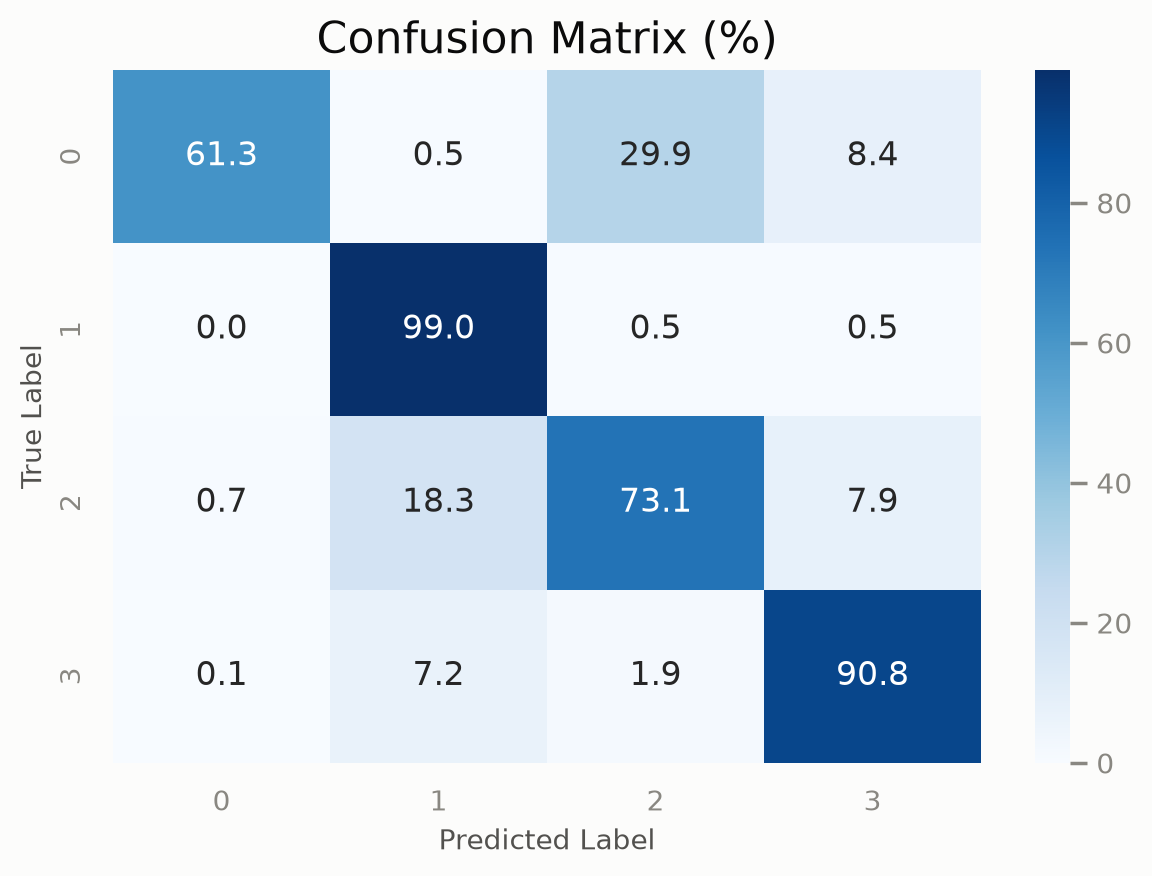

In [ ]:
# Get matched predictions
matched_pred = match_predicted_to_true_labels(y_tensor, labels_pred_1)
cm = ClusteringMetrics.confusion_matrix(y_tensor.clone().detach().to(dtype=torch.long), matched_pred.clone().detach().to(dtype=torch.long))
# Compute confusion matrix using ClusteringMetrics.confusion_matrix
cm_np = cm.numpy().astype(float)
cm_percent = (cm_np.T / cm_np.sum(axis=1)).T * 100
plt.figure()
sns.heatmap(cm_percent, annot=True, fmt='.1f', cmap='Blues')
plt.title('Confusion Matrix (%)')
# Convert the confusion matrix to percentages (normalize per true label)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.gcf()

In [ ]:
# Plot heatmap of the percent confusion matrix
report = ClusteringMetrics.classification_report(y_tensor.clone().detach().to(dtype=torch.long), matched_pred.clone().detach().to(dtype=torch.long))
report_df = pd.DataFrame(report).T
# Generate classification report
# Convert classification report to a DataFrame for display
report_df

,precision,recall,f1-score,support,jaccard,roc_auc
0,0.983936,0.6125,0.755008,800.0,0.606436,0.804432
1,0.433260,0.9900,0.602740,200.0,0.431373,0.948750
2,0.738384,0.7310,0.734673,1000.0,0.580620,0.800750
3,0.860664,0.9080,0.883698,1000.0,0.791630,0.917250


## KL Divergence Analysis

### Kullback-Leibler Divergence Between GMMs

The **KL divergence** $D_{KL}(P \parallel Q)$ measures how one probability distribution $P$ diverges from a reference distribution $Q$:

$$
D_{KL}(P \parallel Q) = \int p(x) \log \frac{p(x)}{q(x)} dx
$$

For Gaussian Mixture Models, we approximate this using Monte Carlo sampling:

$$
D_{KL}(P \parallel Q) \approx \frac{1}{N} \sum_{i=1}^{N} \left[ \log p(x_i) - \log q(x_i) \right]
$$

where $x_i \sim P$ are samples drawn from the first GMM.

**Interpretation:**
- $D_{KL}(P \parallel Q) = 0$ when $P = Q$ (identical distributions)
- $D_{KL}(P \parallel Q) > 0$ always (non-negative)
- **Asymmetric**: $D_{KL}(P \parallel Q) \neq D_{KL}(Q \parallel P)$ in general
- **Lower values** indicate more similar distributions

The plot below shows how KL divergence changes as we vary the number of components in the test GMM while keeping the reference GMM fixed at the true number of components.

Computing KL(p||q) for different numbers of components...


100%|██████████| 14/14 [00:00<00:00, 29.12it/s]


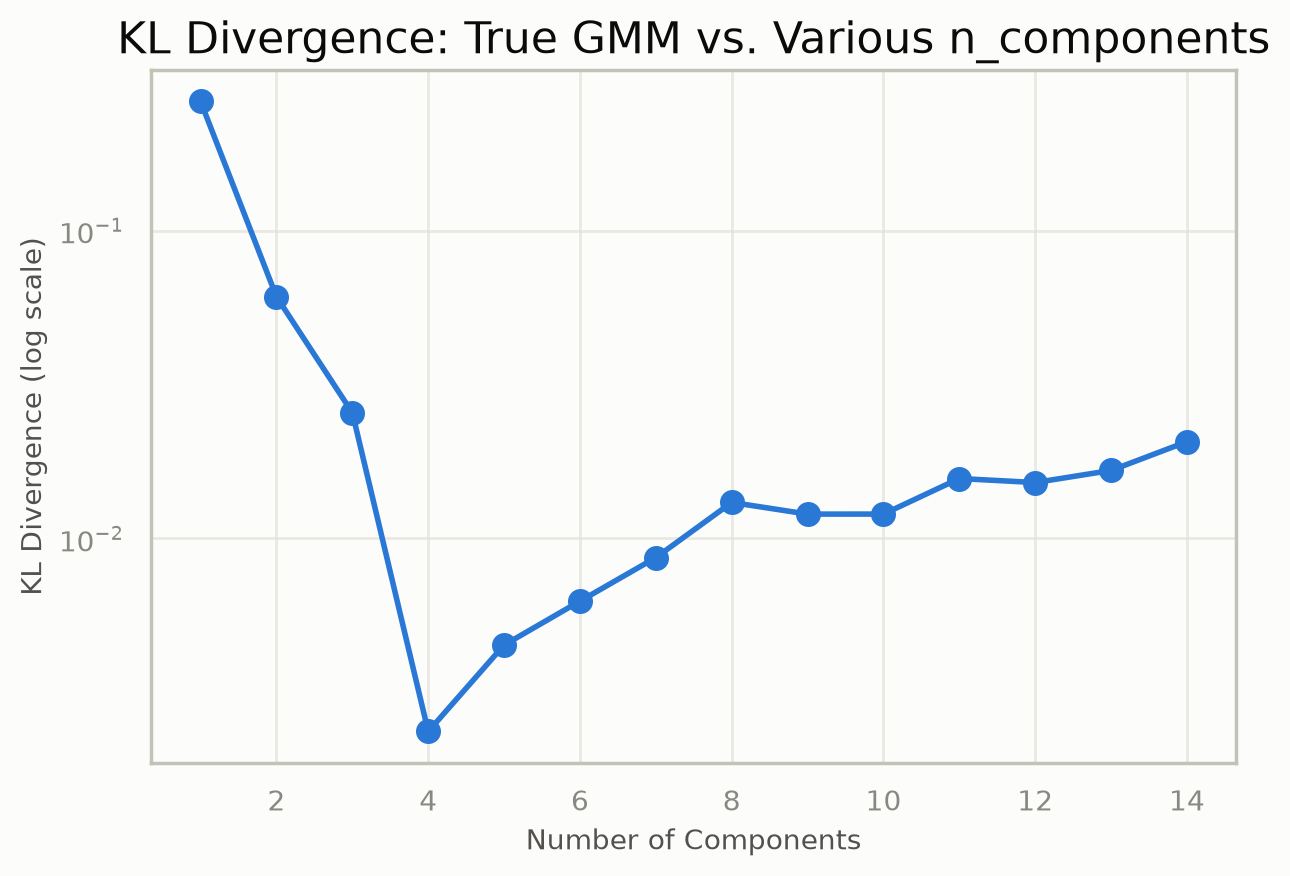

In [ ]:
RUN_KL_DIVERGENCE = True
if RUN_KL_DIVERGENCE:
    print('Computing KL(p||q) for different numbers of components...')
    gmm_true = GaussianMixture(n_features=n_features, n_components=n_components, covariance_type='full', max_iter=MAX_ITER, init_means='kmeans', device=device)
    gmm_true.fit(X_tensor)
    test_range = np.arange(1, 15)
    kl_vals = torch.zeros(len(test_range), device=device)
    for _i, _n in tqdm(enumerate(test_range), total=len(test_range)):
        gmm_test = GaussianMixture(n_features=n_features, n_components=_n, covariance_type='full', max_iter=MAX_ITER, init_means='kmeans', device=device)
        gmm_test.fit(X_tensor)
        kl_vals[_i] = ClusteringMetrics.kl_divergence_gmm(gmm_true, gmm_test, n_samples=10000)
    plt.figure()
    plt.plot(test_range, kl_vals.cpu().numpy(), marker='o')
    plt.yscale('log')
    plt.title('KL Divergence: True GMM vs. Various n_components')
    plt.xlabel('Number of Components')
    plt.ylabel('KL Divergence (log scale)')
    plt.grid(True)
plt.gcf() if RUN_KL_DIVERGENCE else None

## Summary

- Unsupervised indices (Silhouette, Davies-Bouldin, Calinski-Harabasz, Dunn) and information criteria (BIC, AIC) can be swept over `n_components`, but they need not agree on the best $K$.
- Supervised indices compare a clustering with ground truth; `tgmm`'s versions can be checked directly against scikit-learn (AMI uses the exact chance correction).
- Cluster indices are arbitrary, so predictions are matched to true classes before building a confusion matrix or classification report.
- `kl_divergence_gmm` estimates $D_{KL}(P \parallel Q)$ between two fitted mixtures by Monte Carlo sampling.

**Next:** [13 -- Model Selection](13_model_selection.ipynb) for BIC, AIC and ICL sweeps with `select_model`, or [07 -- Sampling](07_sampling.ipynb).